In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import load_dataset

/home/ali/Documents/DL and NLP Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
emotion_dataset = load_dataset('dair-ai/emotion') 

In [ ]:
emotion_dataset 

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [5]:
train_text  = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text   = emotion_dataset['test']['text']
test_label  = emotion_dataset['test']['label']

In [ ]:
label_names = emotion_dataset['train'].features['label'].names 

In [7]:
df_train = pd.DataFrame(
    {
        'text' : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text' : test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [8]:
df_test

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness
...,...,...
1995,i just keep feeling like someone is being unki...,anger
1996,im feeling a little cranky negative after this...,anger
1997,i feel that i am useful to my people and that ...,joy
1998,im feeling more comfortable with derby i feel ...,joy


In [9]:
df_train.value_counts('label')

label
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

<Axes: xlabel='label', ylabel='count'>

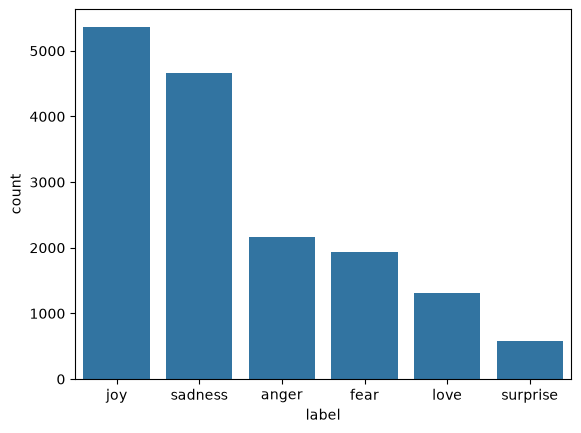

In [10]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

In [11]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words=max_words, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequences = tokenizer.texts_to_sequences(df_train['text'])
test_sequences = tokenizer.texts_to_sequences(df_test['text'])

train_labels = np.array(train_label)
# train_labels
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))
# num_classes



I0000 00:00:1789699175.100545   15108 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789699175.854253   15108 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789699179.079386   15108 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [12]:
train_sequences[5]

[73, 48, 8, 7, 56, 521, 319, 328, 158, 161, 9, 20]

In [13]:
test_sequences[5]

[2, 131, 421, 106, 7, 1515, 1439, 153, 2, 39, 26, 3, 498]

In [14]:
padded_train_sequences = pad_sequences(
    train_sequences,
    maxlen=50,
    padding='post',
    truncating='post'
)

padded_test_sequences = pad_sequences(
    test_sequences,
    maxlen=50,
    padding='post',
    truncating='post'
)

In [15]:
print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequences.shape[1]}")

Vocabulary Size: 15213
Max Sentence Length: 50


In [16]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes      = np.unique(train_labels),
    y            = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

In [17]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
     


In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

/home/ali/Documents/DL and NLP Project/.venv/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
E0000 00:00:1789699181.793365   15108 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [19]:
rnn_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data=(padded_test_sequences, test_labels),
    epochs = 5, # 5 epohs cuz my laptop will explode !!!
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequences, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/5


500/500 ━━━━━━━━━━━━━━━━━━━━ 31s 54ms/step - accuracy: 0.1675 - loss: 1.9452 - val_accuracy: 0.1305 - val_loss: 1.8045
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 52ms/step - accuracy: 0.1606 - loss: 1.8061 - val_accuracy: 0.1640 - val_loss: 1.7619
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 47ms/step - accuracy: 0.1621 - loss: 1.7919 - val_accuracy: 0.1545 - val_loss: 1.7760
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - accuracy: 0.1550 - loss: 1.7835 - val_accuracy: 0.0945 - val_loss: 1.7978
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.1516 - loss: 1.7610 - val_accuracy: 0.0970 - val_loss: 1.7962
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.1640 - loss: 1.7619
RNN Loss: 1.7618913650512695
RNN Accuracy: 0.164000004529953


In [20]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data=(padded_test_sequences, test_labels),
    epochs = 10,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequences, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 69s 127ms/step - accuracy: 0.1581 - loss: 1.7955 - val_accuracy: 0.0805 - val_loss: 1.7917
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 65s 131ms/step - accuracy: 0.1396 - loss: 1.7932 - val_accuracy: 0.0355 - val_loss: 1.8086
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 71s 142ms/step - accuracy: 0.1454 - loss: 1.7928 - val_accuracy: 0.1125 - val_loss: 1.8016
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 68s 135ms/step - accuracy: 0.1559 - loss: 1.7875 - val_accuracy: 0.1455 - val_loss: 1.8039
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.0805 - loss: 1.7917
LSTM Loss: 1.7917377948760986
LSTM Accuracy: 0.08049999922513962


In [21]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequences,
    train_labels,
    validation_data=(padded_test_sequences, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequences, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 54s 96ms/step - accuracy: 0.1471 - loss: 1.7965 - val_accuracy: 0.1115 - val_loss: 1.7991
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 51s 102ms/step - accuracy: 0.1632 - loss: 1.7956 - val_accuracy: 0.1120 - val_loss: 1.8186
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 50s 100ms/step - accuracy: 0.1461 - loss: 1.7947 - val_accuracy: 0.2915 - val_loss: 1.7676
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 39s 78ms/step - accuracy: 0.1694 - loss: 1.7930 - val_accuracy: 0.2850 - val_loss: 1.7621
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 34s 68ms/step - accuracy: 0.1724 - loss: 1.7910 - val_accuracy: 0.2865 - val_loss: 1.7546
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 33s 66ms/step - accuracy: 0.1814 - loss: 1.7807 - val_accuracy: 0.1425 - val_loss: 1.7859
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 85ms/step - accuracy: 0.1934 - loss: 1.7567 - val_accuracy: 0.2290 - val_loss: 1.7984
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 78s 77ms/step - accuracy: 0.2361 - loss: 1.7064 

In [22]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df

,Model,Test Loss,Test Accuracy
2,GRU,1.754649,0.2865
0,RNN,1.761891,0.1640
1,LSTM,1.791738,0.0805


In [23]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') #Output Layer
    #Why i used num_classes in output layer and what will i get from this.
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

/home/ali/Documents/DL and NLP Project/.venv/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [24]:
BiGRU.fit(
    padded_train_sequences,
    train_labels,
    validation_data=(padded_test_sequences, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 104s 197ms/step - accuracy: 0.5958 - loss: 1.0152 - val_accuracy: 0.8975 - val_loss: 0.3702
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 114s 227ms/step - accuracy: 0.9184 - loss: 0.2343 - val_accuracy: 0.9170 - val_loss: 0.2130
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 126s 252ms/step - accuracy: 0.9430 - loss: 0.1563 - val_accuracy: 0.9195 - val_loss: 0.2180
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 117s 233ms/step - accuracy: 0.9554 - loss: 0.1235 - val_accuracy: 0.9225 - val_loss: 0.2212
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 125s 251ms/step - accuracy: 0.9668 - loss: 0.0916 - val_accuracy: 0.9265 - val_loss: 0.2362


63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step


<Axes: >

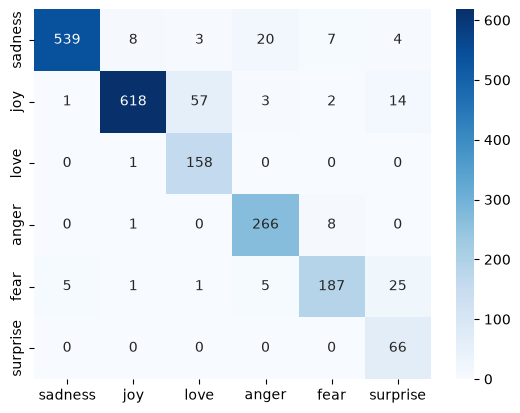

In [26]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequences),axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)


In [27]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [28]:
import os
import pickle

model_dir = os.path.join('..', 'Artifacts')
os.makedirs(model_dir, exist_ok=True)

# Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Model.keras'))

# Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
    pickle.dump(tokenizer, file)